# A Moving Gaussian

*Prof. Maurik Holtrop* — Python version of `Gauss_FreeParticle_moving.nb`

Let's investigate a Gaussian shape, as in Problem 2.22, and then let's see if we can give it some momentum. (We assume that $a, m, t, k, k_1$ are all real, and that $a>0$ and $m>0$.)

We define the wave function at $t=0$ as:
$$
\psi_0(x) = \left(\frac{2a}{\pi}\right)^{1/4} e^{-a x^2}
$$
The momentum space function is then found by integrating:
$$
\phi(k) = \int_{-\infty}^{\infty} \frac{1}{\sqrt{2\pi}}\, \psi_0(x)\, e^{-ikx}\, dx = \frac{e^{-\frac{k^2}{4a}}}{(2\pi a)^{1/4}}
$$
If we take this function, but now shift it in $k$, so $k \to k - k_1$, and then integrate the result back to position space, we find the initial wave function of a *moving* Gaussian:
$$
\phi(k) = \frac{e^{-\frac{(k-k_1)^2}{4a}}}{(2\pi a)^{1/4}}
\qquad\Longrightarrow\qquad
\psi_0(x) = \int_{-\infty}^{\infty}\frac{1}{\sqrt{2\pi}}\,\phi(k)\, e^{ikx}\, dk = \left(\frac{2a}{\pi}\right)^{1/4} e^{x(ik_1 - a x)}
$$
So if we add a complex phase that depends on $x$, $e^{ik_1 x}$, we get a moving wave. We compute the wave function for all $t$ by integrating $\phi(k)$, now including the energy term:
$$
\psi_{k_1}(x,t) = \int_{-\infty}^{\infty}\frac{1}{\sqrt{2\pi}}\,\phi(k)\, e^{ikx}\, e^{-i\frac{\hbar k^2 t}{2m}}\, dk
= \left(\frac{2a}{\pi}\right)^{1/4} \frac{1}{\sqrt{1+\frac{2i\hbar a t}{m}}}\;
\exp\left[-\frac{i\frac{\hbar k_1^2}{2m}t - i k_1 x + a x^2}{1+\frac{2i\hbar a t}{m}}\right]
$$

## A higher frequency wave inside the Gaussian envelope

The plain Gaussian $e^{-ax^2}$ is built from waves with $k$ clustered around $k=0$. We can also build a packet that looks like a *higher frequency wave* inside a Gaussian envelope, by multiplying with $\cos(k_c x)$:
$$
\psi_0(x) = \mathcal{N}\left(\frac{2a}{\pi}\right)^{1/4} e^{-a x^2}\cos(k_c x)\, e^{ik_1 x},
\qquad \mathcal{N} = \left[\frac{1+e^{-k_c^2/2a}}{2}\right]^{-1/2}
$$
Since $\cos(k_c x) = \tfrac12\left(e^{ik_cx}+e^{-ik_cx}\right)$, this is the sum of two Gaussians in $k$-space, centered at $k_1+k_c$ and $k_1-k_c$:
$$
\phi(k) = \frac{\mathcal{N}}{2}\left[\frac{e^{-\frac{(k-k_1-k_c)^2}{4a}}}{(2\pi a)^{1/4}} + \frac{e^{-\frac{(k-k_1+k_c)^2}{4a}}}{(2\pi a)^{1/4}}\right]
$$
The two parameters therefore do different things:

* **Carrier wave number $k_c$** raises the frequencies of the waves that make up the packet, but the packet as a whole has $\langle p\rangle = \hbar k_1$, not $\hbar k_c$. With $k_1=0$ it is a *standing* wave: it holds equal amounts of $+k_c$ and $-k_c$, so as time goes on it splits into two packets moving in opposite directions.
* **Momentum $k_1$** shifts *all* the $k$ components by the same amount, and so gives the packet a net momentum $\hbar k_1$ and a group velocity $v_g = \hbar k_1/m$.

Because the Schrödinger equation is linear, the exact solution is just the sum of two moving Gaussians, $\psi(x,t) = \tfrac{\mathcal N}{2}\left[\psi_{k_1+k_c}(x,t) + \psi_{k_1-k_c}(x,t)\right]$.

## Numerical method

In `QM5_TimePropagation_of_WF` we compared two ways to propagate a wave function:

1. **Direct evaluation of $U(\Delta t) = e^{-iH\Delta t/\hbar}$ as a matrix.** Each step costs $\mathcal{O}(N^2)$, $\Delta t$ must be tiny for stability, and the result is not exactly unitary.
2. **Split-step FFT.** This method alternates between $x$-space (potential) and $k$-space (kinetic energy), and each step costs $\mathcal{O}(N\log N)$.

For a **free particle** ($V=0$) the FFT method gets much better still. The Hamiltonian $H = \hbar^2k^2/2m$ is *diagonal* in $k$-space, so
$$
\widetilde\psi(k,t) = \widetilde\psi(k,0)\, e^{-i\hbar k^2 t/2m}
$$
is **exact for any $t$**, with no time stepping at all. We FFT the initial wave function once. Each frame (each slider position) then costs one complex multiplication plus one inverse FFT. On a grid of $2^{14}$ points that takes well under a millisecond, so the sliders respond immediately.

## Units

We use the same units as the Mathematica notebook: $x$ in fm, $k$ in fm$^{-1}$, a proton mass $mc^2 = 938$ MeV, and $\hbar c = 197.3$ MeV fm, so time is in fm/$c$. The Schrödinger equation is non-relativistic and knows nothing about $c$, so don't be alarmed when large $k$ gives "velocities" faster than light.

In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

In [2]:
# Physical constants (units: fm, MeV, time in fm/c)
hbar = 197.3     # hbar*c in MeV fm
m = 938.         # m*c^2 in MeV  ->  hbar/m = hbar*c/(m*c^2) in fm (times c)
a = 2.0          # Gaussian width parameter in fm^-2  (sigma = 1/sqrt(2a) = 0.5 fm)

# Grid. Power of 2 for fast FFTs. The box must be large enough that the packet never
# wraps around (the FFT is periodic), and dx small enough to resolve the largest k.
N = 2**14
x_min, x_max = -60., 60.
dx = (x_max - x_min)/N
x = x_min + np.arange(N)*dx
k = 2*np.pi*np.fft.fftfreq(N, d=dx)   # k values in the (unshifted) order numpy's FFT uses
print(f"dx = {dx:.4f} fm,  k_max = {np.pi/dx:.1f} fm^-1")

dx = 0.0073 fm,  k_max = 428.9 fm^-1


In [3]:
def psi_initial(x, kc, k1):
    '''Normalized Gaussian with a carrier wave cos(kc x) and momentum hbar*k1, at t=0.'''
    norm = (2*a/np.pi)**0.25/np.sqrt((1 + np.exp(-kc**2/(2*a)))/2)
    return norm*np.exp(-a*x**2)*np.cos(kc*x)*np.exp(1j*k1*x)

def psi_analytic_k1(x, t, k1):
    '''The exact moving Gaussian psi_{k1}(x,t) from the formula above.'''
    D = 1 + 2j*hbar*a*t/m
    return (2*a/np.pi)**0.25/np.sqrt(D)*np.exp(-(1j*hbar*k1**2*t/(2*m) - 1j*k1*x + a*x**2)/D)

def psi_analytic(x, t, kc, k1):
    '''Exact solution for the Gaussian with carrier: the sum of two moving Gaussians.'''
    norm = 1/np.sqrt((1 + np.exp(-kc**2/(2*a)))/2)
    return norm/2*(psi_analytic_k1(x, t, k1 + kc) + psi_analytic_k1(x, t, k1 - kc))

def psi_evolve(phi0, t):
    '''Exact free-particle propagation: multiply by exp(-i hbar k^2 t/2m) in k-space.'''
    return np.fft.ifft(phi0*np.exp(-1j*hbar*k**2*t/(2*m)))

### Check the numerical method against the exact solution

Before we trust the sliders, we compare the FFT result to the analytic formula and check that the normalization is preserved.

In [4]:
for kc, k1, t in [(0, 30, 1.0), (20, 0, 2.0), (30, -20, 1.5)]:
    phi0 = np.fft.fft(psi_initial(x, kc, k1))
    psi_num = psi_evolve(phi0, t)
    err = np.max(np.abs(psi_num - psi_analytic(x, t, kc, k1)))
    norm = np.sum(np.abs(psi_num)**2)*dx
    x_avg = np.sum(x*np.abs(psi_num)**2)*dx
    print(f"kc={kc:3}  k1={k1:4}  t={t:3.1f}:  max|psi_num - psi_exact| = {err:.1e},  "
          f"norm = {norm:.6f},  <x> = {x_avg:6.2f}  (expect hbar k1 t/m = {hbar*k1*t/m:6.2f})")

%timeit psi_evolve(phi0, 1.0)

kc=  0  k1=  30  t=1.0:  max|psi_num - psi_exact| = 2.5e-14,  norm = 1.000000,  <x> =   6.31  (expect hbar k1 t/m =   6.31)
kc= 20  k1=   0  t=2.0:  max|psi_num - psi_exact| = 1.6e-14,  norm = 1.000000,  <x> =  -0.00  (expect hbar k1 t/m =   0.00)
kc= 30  k1= -20  t=1.5:  max|psi_num - psi_exact| = 4.4e-14,  norm = 1.000000,  <x> =  -6.31  (expect hbar k1 t/m =  -6.31)
387 μs ± 4.48 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


## Interactive plot

* **time**: the time $t$ in fm/$c$. Press ▶ to animate.
* **carrier $k_c$**: the frequency of the wave inside the Gaussian envelope.
* **momentum $k_1$**: the momentum $p = \hbar k_1$ given to the whole packet.

The top panel shows $\mathrm{Re}\,\psi$, $\mathrm{Im}\,\psi$ and the probability density $|\psi|^2$. The bottom panel shows the momentum distribution $|\phi(k)|^2$. It does **not** change with time for a free particle, but it shows clearly which waves make up the packet.

Things to try:
* Set $k_c = k_1 = 0$ and move the time slider. The Gaussian spreads, as in Problem 2.22.
* Increase $k_1$. The packet moves to the right, and the wiggles in $\mathrm{Re}\,\psi$ appear.
* Set $k_1=0$ and increase $k_c$. At $t=0$ this looks like a moving packet, but it is a standing wave. Watch it split in two!
* Combine $k_c$ and $k_1$. Two packets move with velocities $\hbar(k_1\pm k_c)/m$.
* Look at the waves at the front and back of a spreading packet. The fast (high $k$) waves get out ahead and the slow ones lag behind. This is dispersion.

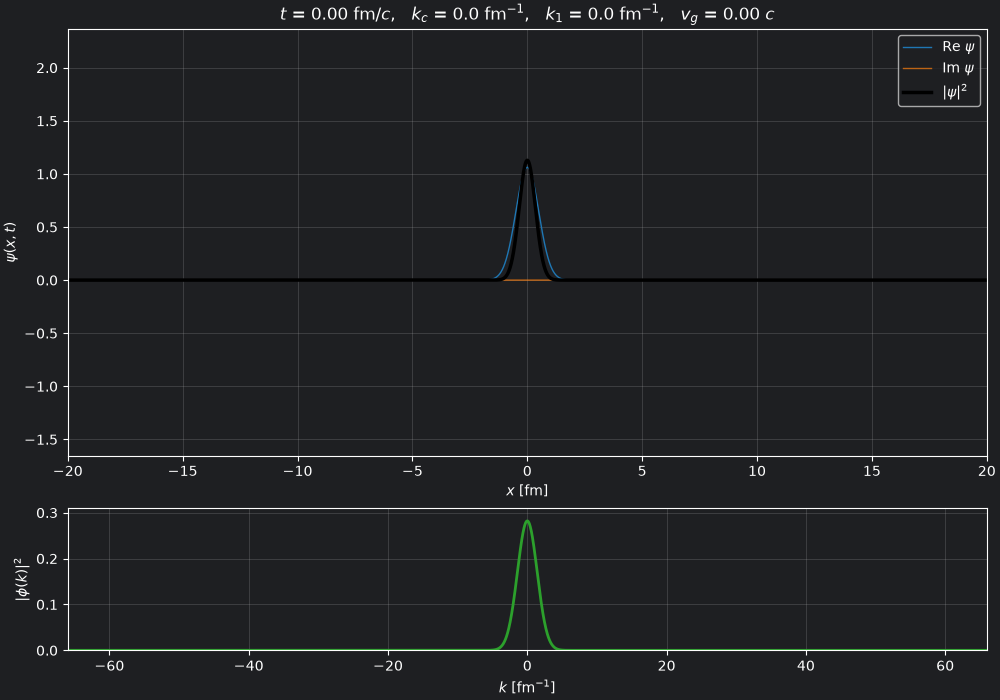

In [7]:
x_view = (-20., 20.)       # plot range in x (fm)
t_max = 10.0                # maximum time on the slider (fm/c)
k_slider_max = 30.         # maximum for the k_c and k_1 sliders (fm^-1)

in_view = (x >= x_view[0]) & (x <= x_view[1])   # only plot the visible part, which keeps redraws fast
xv = x[in_view]
k_sorted = np.fft.fftshift(k)
k_view = np.abs(k_sorted) <= 2.2*k_slider_max

state = {'phi0': None}

def set_initial(kc, k1):
    state['phi0'] = np.fft.fft(psi_initial(x, kc, k1))

plt.close('Moving Gaussian')
fig, (ax, axk) = plt.subplots(2, 1, figsize=(10, 7), num='Moving Gaussian', layout='constrained',
                              gridspec_kw={'height_ratios': [3, 1]})
fig.canvas.header_visible = False

peak = np.sqrt(2*a/np.pi)                # |psi|^2 at x=0, t=0 for a plain Gaussian
ax.set_xlim(*x_view)
ax.set_ylim(-1.1*np.sqrt(2*peak), 2.1*peak)
ax.set_xlabel(r'$x$ [fm]')
ax.set_ylabel(r'$\psi(x,t)$')
ax.grid(alpha=0.3)
line_re, = ax.plot([], [], lw=1, color='tab:blue', label=r'Re $\psi$')
line_im, = ax.plot([], [], lw=1, color='tab:orange', alpha=0.7, label=r'Im $\psi$')
line_p2, = ax.plot([], [], lw=2.5, color='black', label=r'$|\psi|^2$')
ax.legend(loc='upper right')
title = ax.set_title('')

axk.set_xlim(k_sorted[k_view][0], k_sorted[k_view][-1])
axk.set_ylim(0, 1.1/np.sqrt(2*np.pi*a))
axk.set_xlabel(r'$k$ [fm$^{-1}$]')
axk.set_ylabel(r'$|\phi(k)|^2$')
axk.grid(alpha=0.3)
line_k, = axk.plot([], [], lw=2, color='tab:green')

def update(change=None):
    kc, k1, t = s_kc.value, s_k1.value, s_t.value
    if change is None or change['owner'] is not s_t:     # only re-FFT when the initial state changes
        set_initial(kc, k1)
        phi = np.fft.fftshift(state['phi0'])*dx/np.sqrt(2*np.pi)   # continuum normalization
        line_k.set_data(k_sorted[k_view], np.abs(phi[k_view])**2)
    psi = psi_evolve(state['phi0'], t)[in_view]
    line_re.set_data(xv, psi.real)
    line_im.set_data(xv, psi.imag)
    line_p2.set_data(xv, np.abs(psi)**2)
    title.set_text(rf'$t$ = {t:.2f} fm/$c$,   $k_c$ = {kc:.1f} fm$^{{-1}}$,   '
                   rf'$k_1$ = {k1:.1f} fm$^{{-1}}$,   $v_g$ = {hbar*k1/m:.2f} $c$')
    fig.canvas.draw_idle()

slider_layout = widgets.Layout(width='600px')
style = {'description_width': '120px'}
s_t = widgets.FloatSlider(value=0., min=0., max=t_max, step=0.005, readout_format='.3f',
                          description='time t [fm/c]', layout=slider_layout, style=style)
s_kc = widgets.FloatSlider(value=0., min=0., max=k_slider_max, step=0.1,
                           description='carrier kc [1/fm]', layout=slider_layout, style=style)
s_k1 = widgets.FloatSlider(value=0., min=-k_slider_max, max=k_slider_max, step=0.1,
                           description='momentum k1 [1/fm]', layout=slider_layout, style=style)
play = widgets.Play(value=0, min=0, max=400, step=1, interval=30, description='Animate')
play.observe(lambda c: setattr(s_t, 'value', c['new']*t_max/play.max), names='value')

for s in (s_t, s_kc, s_k1):
    s.observe(update, names='value')
update()

widgets.VBox([widgets.HBox([play, s_t]), s_kc, s_k1])

## Snapshot sequence


To print or save a figure, here is the static version of the Mathematica plot: $|\psi|^2$ at a sequence of times. The color goes from blue to green as $t$ increases. Change `kc` and `k1` to see the other cases.

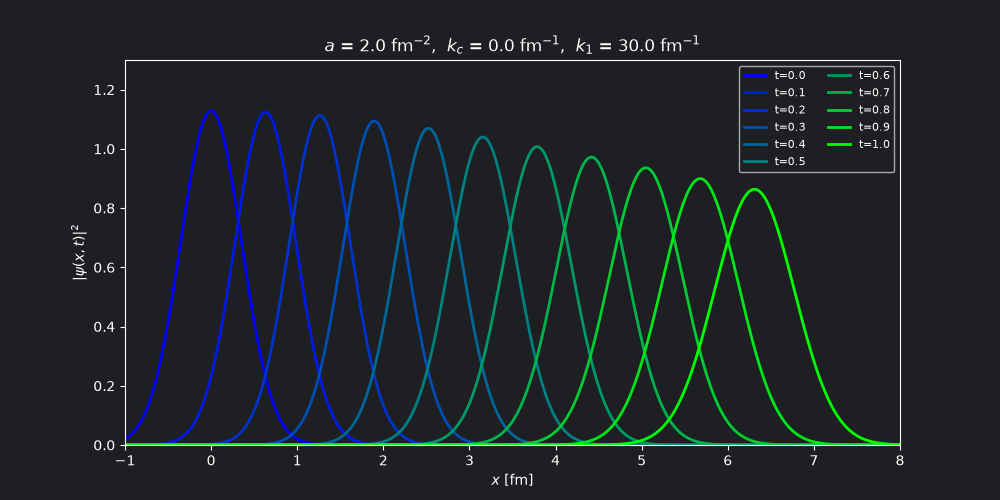

In [6]:
kc, k1 = 0., 30.
phi0 = np.fft.fft(psi_initial(x, kc, k1))
fig2, ax2 = plt.subplots(figsize=(10, 5), num='Snapshots')
for i in range(11):
    t = i/10
    ax2.plot(x, np.abs(psi_evolve(phi0, t))**2, lw=2, color=(0, i/10, (10 - i)/10), label=f't={t:.1f}')
ax2.set_xlim(-1, 8)
ax2.set_ylim(0, 1.3)
ax2.set_xlabel(r'$x$ [fm]')
ax2.set_ylabel(r'$|\psi(x,t)|^2$')
ax2.set_title(rf'$a$ = {a} fm$^{{-2}}$,  $k_c$ = {kc} fm$^{{-1}}$,  $k_1$ = {k1} fm$^{{-1}}$')
ax2.legend(ncol=2, fontsize=8)
plt.show()